# Rolulabo. Análisis y modelos

Sigue las fases de CRISP-DM. Notebook de evidencia. Ejecuta el pipeline de `src/` y muestra los resultados clave de cada etapa. Toda la lógica vive en los módulos de `src/`, aquí solo se llaman y se inspeccionan.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
import etl, loss_model, delivery, segmentation, cross, hypotheses, decision_rules

## 1. ETL y calidad de datos

Validaciones de esquema, nulos, duplicados, reglas de dominio y consistencia por pedido. También se verifican dos hallazgos estructurales que cambian el planteamiento. El descuento es único por estado y subcategoría, y el costo unitario es fijo por producto.

In [2]:
q = etl.run()
pd.Series(q, dtype=object)

filas_crudas                                                                        9994
columnas_esperadas_ok                                                               True
nulos_totales                                                                          0
duplicados_exactos_eliminados                                                          1
envio_antes_de_pedido                                                                  0
ventas_no_positivas                                                                    0
cantidad_no_positiva                                                                   0
descuento_fuera_de_rango                                                               0
paises                                                                   [United States]
pedidos_inconsistentes                                                                 0
product_id_reutilizados                                                               32
combinaciones_estado_

In [3]:
lines = pd.read_csv(ROOT / "data/processed/lines.csv", parse_dates=["order_date"])
lines[["sales", "quantity", "discount", "profit", "list_price", "unit_cost", "breakeven_discount"]].describe().round(3)

,sales,quantity,discount,profit,list_price,unit_cost,breakeven_discount
count,9993.000,9993.000,9993.000,9993.000,9993.000,9993.000,9993.000
mean,229.853,3.790,0.156,28.661,75.559,53.111,0.341
std,623.276,2.225,0.206,234.271,188.967,122.254,0.136
min,0.444,1.000,0.000,-6599.978,0.990,0.544,-0.000
25%,17.280,2.000,0.000,1.731,6.480,3.474,0.260
50%,54.480,3.000,0.200,8.671,19.980,12.934,0.340
75%,209.940,5.000,0.200,29.364,76.980,54.522,0.470
max,22638.480,14.000,0.800,8399.976,7546.160,4074.926,0.500


## 2. Análisis exploratorio

In [4]:
eda = lines.groupby("sub_category").agg(lineas=("row_id","size"), ventas=("sales","sum"), utilidad=("profit","sum"),
        perdida_pct=("is_loss","mean"), descuento_prom=("discount","mean")).sort_values("utilidad")
eda.round(3)

,lineas,ventas,utilidad,perdida_pct,descuento_prom
sub_category,,,,,
Tables,319,206965.532,-17725.481,0.636,0.261
Bookcases,228,114879.996,-3472.556,0.478,0.211
Supplies,190,46673.538,-1189.100,0.174,0.077
Fasteners,217,3024.280,949.518,0.055,0.082
Machines,115,189238.631,3384.757,0.383,0.306
Labels,364,12486.312,5546.254,0.000,0.069
Art,796,27118.792,6527.787,0.000,0.075
Envelopes,254,16476.402,6964.177,0.000,0.080
Furnishings,957,91705.164,13059.144,0.175,0.138


In [5]:
lines.groupby("state").agg(descuento_prom=("discount","mean"), utilidad=("profit","sum")).sort_values("descuento_prom", ascending=False).head(12).round(3)

,descuento_prom,utilidad
state,,
Illinois,0.390,-12607.887
Texas,0.370,-25729.356
Pennsylvania,0.329,-15559.960
Ohio,0.325,-16959.318
Colorado,0.316,-6527.858
Arizona,0.304,-3427.925
Florida,0.299,-3399.302
Tennessee,0.291,-5341.694
Oregon,0.289,-1190.470


## 3. Problema 1. Líneas con pérdida

Partición temporal (2014 a 2016 entrenamiento, 2017 prueba), validación cruzada temporal para hiperparámetros y umbral, comparación contra la regla descuento > 20%.

In [6]:
r1 = loss_model.run()
pd.DataFrame(r1["modelos"]).T[["roc_auc","pr_auc","f1","precision","recall","perdida_detectada_pct"]].astype(float).round(3)

Seleccion de modelos con validacion temporal


  Regresion logistica: CV PR-AUC 0.943 params {'C': 10.0}


  Arbol de decision: CV PR-AUC 0.938 params {'max_depth': None, 'min_samples_leaf': 30}


  Random forest: CV PR-AUC 0.937 params {'max_depth': 10, 'min_samples_leaf': 1}


  Gradient boosting: CV PR-AUC 0.952 params {'learning_rate': 0.05, 'max_depth': 6}


,roc_auc,pr_auc,f1,precision,recall,perdida_detectada_pct
Linea base sin modelo,0.500,0.187,0.000,0.000,0.000,NaN
Regla descuento > 20%,0.940,0.814,0.826,0.976,0.716,0.893
Regresion logistica,0.985,0.945,0.842,0.825,0.860,0.946
Arbol de decision,0.986,0.944,0.859,0.919,0.806,0.924
Random forest,0.988,0.956,0.864,0.843,0.885,0.975
Gradient boosting,0.991,0.967,0.890,0.868,0.913,0.968


In [7]:
print("Modelo elegido:", r1["modelo_elegido"])
print("IC 95% modelo:", r1["ic95_modelo_elegido"])
print("IC 95% regla:", r1["ic95_regla"])
print("Descuento exacto de 20%:", r1["descuento_20"])
pd.Series(r1["importancia_permutacion"]).round(4)

Modelo elegido: Gradient boosting
IC 95% modelo: {'f1_ic95': [0.87088557759394, 0.9081736306094667], 'pr_auc_ic95': [0.9591022905911127, 0.9748199979851913]}
IC 95% regla: {'f1_ic95': [0.8015047526032973, 0.8506189352147924], 'pr_auc_ic95': [0.7896286250261394, 0.8376111781601786]}
Descuento exacto de 20%: {'lineas': 1223, 'perdidas': 169, 'regla_detecta': 0, 'modelo_detecta': 117, 'modelo_falsos_positivos': 74}


discount          0.7453
sub_category      0.0864
log_list_price    0.0369
category          0.0109
month             0.0021
quantity          0.0016
segment           0.0005
ship_mode        -0.0001
region           -0.0004
dtype: float64

In [8]:
print((ROOT / "reports/metrics/arbol_reglas.txt").read_text())

|--- num__discount <= 0.250
|   |--- num__discount <= 0.125
|   |   |--- num__discount <= 0.050
|   |   |   |--- class: 0
|   |   |--- num__discount >  0.050
|   |   |   |--- class: 0
|   |--- num__discount >  0.125
|   |   |--- cat__sub_category_Storage <= 0.500
|   |   |   |--- class: 0
|   |   |--- cat__sub_category_Storage >  0.500
|   |   |   |--- class: 1
|--- num__discount >  0.250
|   |--- cat__sub_category_Copiers <= 0.500
|   |   |--- num__discount <= 0.425
|   |   |   |--- class: 1
|   |   |--- num__discount >  0.425
|   |   |   |--- class: 1
|   |--- cat__sub_category_Copiers >  0.500
|   |   |--- class: 0



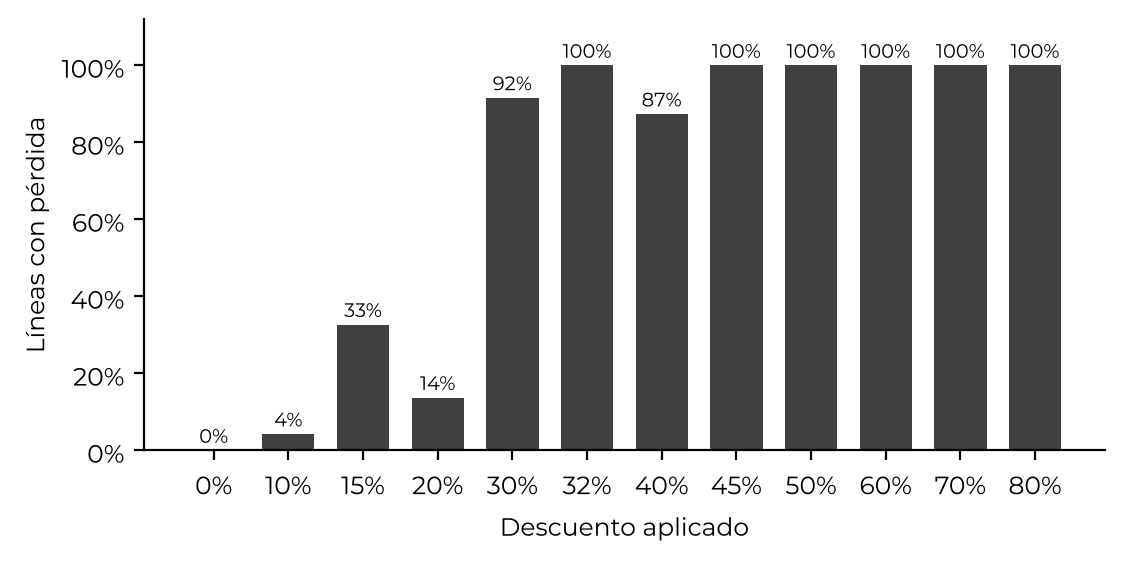

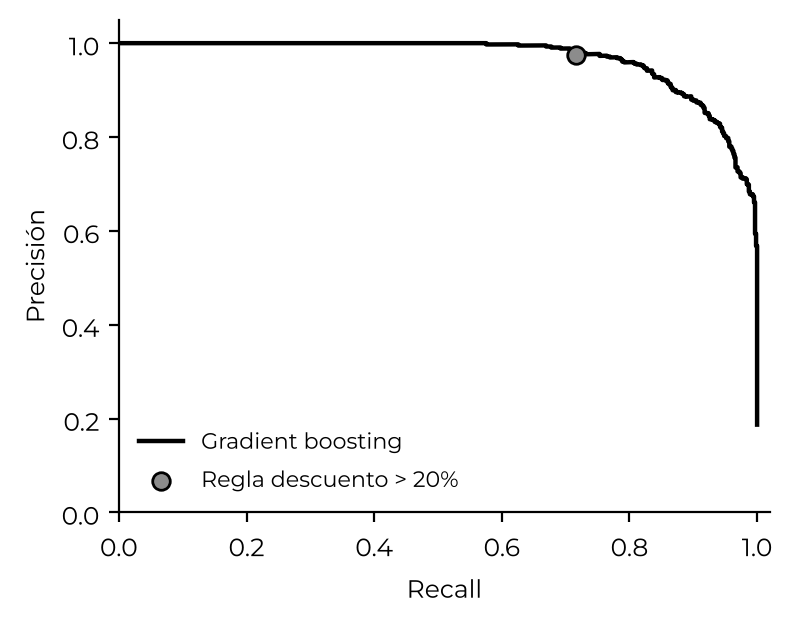

In [9]:
display(Image(ROOT / "reports/figures/f1_perdida_por_descuento.png")); display(Image(ROOT / "reports/figures/f2_precision_recall.png"))

### Topes de descuento y simulación de política sobre 2017

In [10]:
caps = pd.read_csv(ROOT / "reports/metrics/topes_descuento.csv")
caps[["sub_category","descuento_prom_actual","descuento_max_actual","perdida_pct_hist","tope_costo","tope_modelo","tope_recomendado"]].round(3)

,sub_category,descuento_prom_actual,descuento_max_actual,perdida_pct_hist,tope_costo,tope_modelo,tope_recomendado
0,Tables,0.259,0.5,0.628,0.10,0.15,0.10
1,Bookcases,0.209,0.7,0.467,0.05,0.15,0.05
2,Supplies,0.079,0.2,0.183,0.00,0.15,0.00
3,Fasteners,0.089,0.2,0.065,0.00,0.25,0.00
4,Labels,0.071,0.2,0.000,0.45,0.30,0.30
5,Art,0.073,0.2,0.000,0.25,0.30,0.25
6,Envelopes,0.078,0.2,0.000,0.45,0.30,0.30
7,Machines,0.309,0.7,0.402,0.25,0.25,0.25
8,Furnishings,0.143,0.6,0.187,0.15,0.25,0.15
9,Appliances,0.161,0.8,0.133,0.25,0.25,0.25


In [11]:
sim = r1["simulacion_2017"]
print({k: v for k, v in sim.items() if k != "escenarios"})
pd.DataFrame(sim["escenarios"]).round(1)

{'lineas_prueba': 3312, 'lineas_afectadas': 925, 'lineas_afectadas_pct': 0.2792874396135266, 'utilidad_actual': 93439.26960000001, 'ventas_actuales': 733215.2552, 'lineas_perdida_actual': 620, 'lineas_perdida_simulada': 49, 'monto_perdida_actual': 53836.1934, 'monto_perdida_simulada': 761.4618000000003, 'utilidad_afectadas_antes': -46057.562600000005, 'utilidad_afectadas_despues': 43162.78869999999, 'perdida_volumen_equilibrio': None}


,perdida_volumen,utilidad,ventas,delta_utilidad
0,0.0,182659.6,822435.6,89220.4
1,0.1,178343.3,791783.2,84904.1
2,0.2,171868.9,745804.6,78429.7
3,0.5,161078.2,669173.5,67639.0
4,1.0,139496.8,515911.4,46057.6


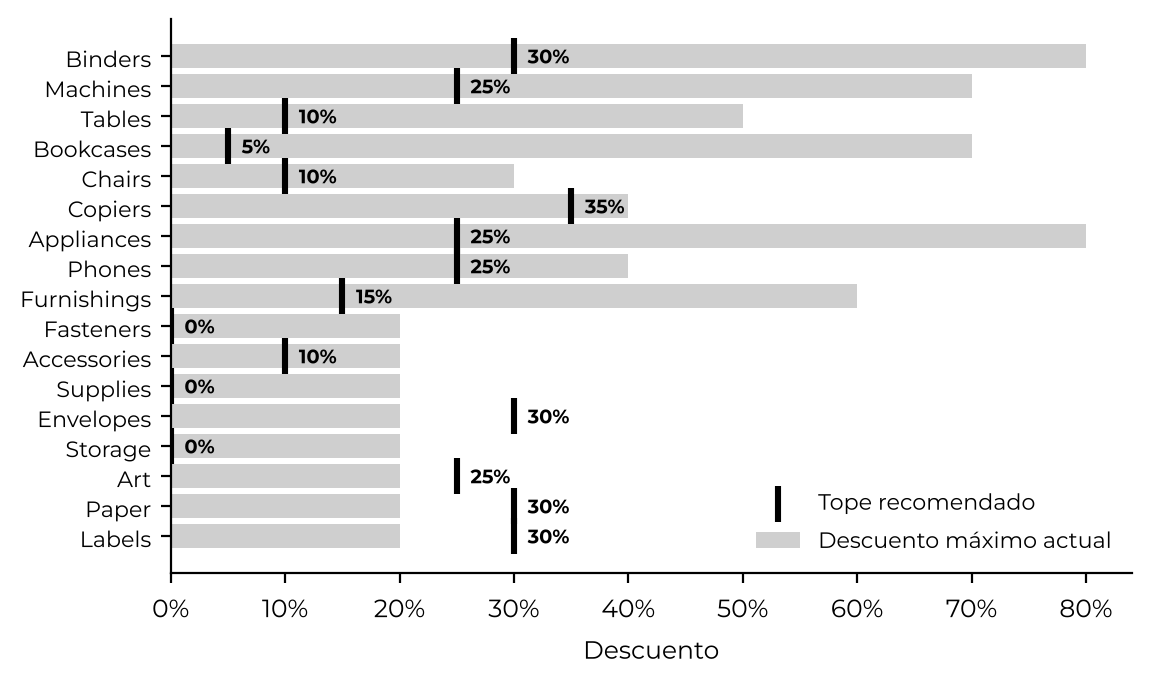

In [12]:
display(Image(ROOT / "reports/figures/f3_topes_descuento.png"))

## 4. Problema 2. Entregas fuera de tiempo

In [13]:
r2 = delivery.run()
pd.DataFrame({m: {k: v for k, v in d.items() if k != "distribucion"} for m, d in r2["descripcion"].items() if isinstance(d, dict)}).T

,pedidos,promesa_dias,fuera_de_tiempo_pct,dias_mediana,dias_p90,dias_p95,dias_max
Same Day,264.0,0.0,0.045455,0.0,0.0,0.0,1.0
First Class,787.0,2.0,0.401525,2.0,3.0,3.0,4.0
Second Class,964.0,3.0,0.411826,3.0,5.0,5.0,5.0
Standard Class,2994.0,5.0,0.301937,5.0,7.0,7.0,7.0


In [14]:
print("Pruebas significativas con Bonferroni:", r2["pruebas_significativas"], "de", len(r2["pruebas_chi2"]))
pd.DataFrame(r2["pruebas_chi2"]).sort_values("p_valor").head(8).round(4)

Pruebas significativas con Bonferroni: 0 de 24


,modalidad,variable,chi2,gl,p_valor,v_cramer,significativo_bonferroni
14,Second Class,main_category,15.7248,6,0.0153,0.0904,False
6,First Class,region,12.7677,6,0.0469,0.0901,False
0,Same Day,region,7.9387,3,0.0473,0.1734,False
8,First Class,main_category,5.5774,4,0.2330,0.0596,False
21,Standard Class,month,37.4386,33,0.2726,0.0646,False
23,Standard Class,year,10.0542,9,0.3461,0.0335,False
20,Standard Class,main_category,6.5637,6,0.3631,0.0331,False
13,Second Class,segment,6.5563,6,0.3638,0.0583,False


In [15]:
pd.DataFrame(r2["modelos"]).round(3)

,modalidad,modelo,auc_prueba,pedidos_prueba,positivos_prueba
0,Same Day,Regresion logistica,0.579,89,5
1,Same Day,Gradient boosting,0.176,89,5
2,First Class,Regresion logistica,0.457,284,119
3,First Class,Gradient boosting,0.490,284,119
4,Second Class,Regresion logistica,0.523,324,133
5,Second Class,Gradient boosting,0.521,324,133
6,Standard Class,Regresion logistica,0.462,990,312
7,Standard Class,Gradient boosting,0.496,990,312
8,Todas (incluye modalidad),Gradient boosting,0.555,1687,569


In [16]:
pd.DataFrame(r2["sensibilidad_promesa"]).round(3)

,modalidad,escenario,promesa_dias,cumplimiento
0,Same Day,actual,0,0.955
1,Same Day,actual + 1,1,1.000
2,Same Day,p95,0,0.955
3,First Class,actual,2,0.598
4,First Class,actual + 1,3,0.999
5,First Class,p95,3,0.999
6,Second Class,actual,3,0.588
7,Second Class,actual + 1,4,0.790
8,Second Class,p95,5,1.000
9,Standard Class,actual,5,0.698


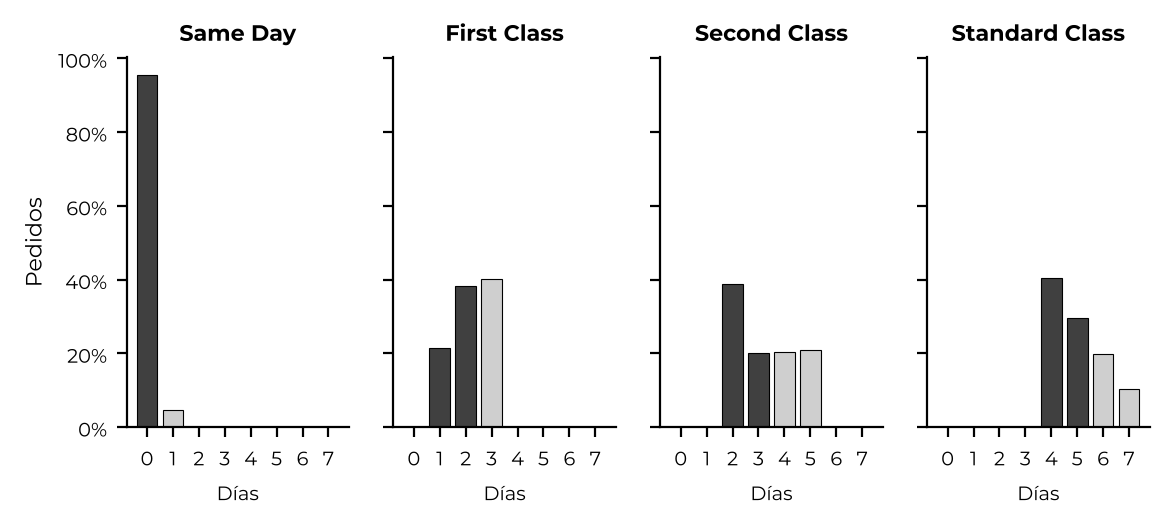

In [17]:
display(Image(ROOT / "reports/figures/f4_dias_envio.png"))

## 5. Problema 3. Segmentación de clientes

In [18]:
r3 = segmentation.run()
pd.DataFrame(r3["seleccion_k"]).round(3)

,k,inercia,silueta,davies_bouldin
0,2,3020.013,0.312,1.588
1,3,2495.541,0.278,1.386
2,4,2141.219,0.222,1.335
3,5,1910.648,0.210,1.330
4,6,1762.450,0.186,1.392
5,7,1624.719,0.190,1.329
6,8,1521.095,0.180,1.343


In [19]:
print("k elegido:", r3["k_elegido"]); print("Estabilidad:", r3["estabilidad"]); print("Alternativas:", r3["estabilidad_alternativas"])
pd.DataFrame(r3["perfiles"]).set_index("nombre").round(3)

k elegido: 4
Estabilidad: {'ari_semillas_media': 0.9762112637692233, 'ari_semillas_min': 0.9390496744108362, 'ari_bootstrap_media': 0.7152891536732368, 'ari_bootstrap_p05': 0.3464644400686865}
Alternativas: {3: {'ari_semillas_media': 0.9812263483446306, 'ari_semillas_min': 0.9289714470170496, 'ari_bootstrap_media': 0.6306419302663141, 'ari_bootstrap_p05': 0.23385756324081994}, 5: {'ari_semillas_media': 0.9538135275877508, 'ari_semillas_min': 0.8596205074874328, 'ari_bootstrap_media': 0.7600482160468061, 'ari_bootstrap_p05': 0.5139704497917712}}


,cluster,clientes,recency,frequency,monetary,profit,margin,avg_discount,loss_line_share,late_rate,ventas_pct,utilidad_pct,perdidas_pct,clientes_pct
nombre,,,,,,,,,,,,,,
Alto valor rentable,0,347,90.617,7.850,4284.785,836.053,0.184,0.124,0.134,0.332,0.647,1.013,0.290,0.438
Cazadores de descuento,1,201,87.567,6.612,2601.031,-226.424,-0.054,0.244,0.336,0.319,0.228,-0.159,0.622,0.253
Inactivos,2,73,595.397,3.342,1362.290,45.700,-0.002,0.216,0.267,0.279,0.043,0.012,0.067,0.092
Compradores ocasionales,3,172,143.593,4.140,1092.121,223.686,0.210,0.100,0.089,0.324,0.082,0.134,0.022,0.217


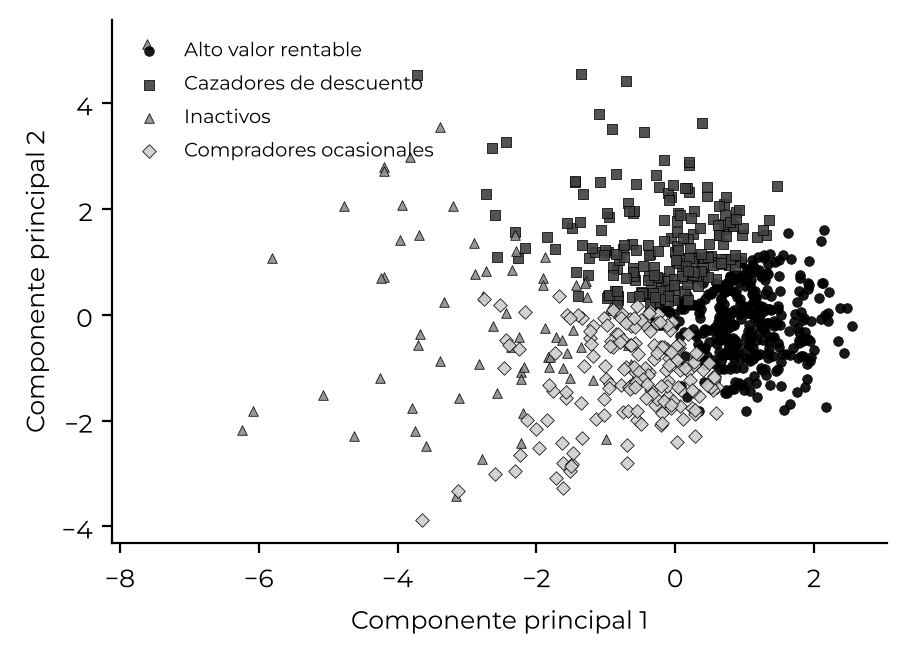

In [20]:
display(Image(ROOT / "reports/figures/f5_clusters_pca.png"))

## 6. Lectura cruzada

In [21]:
r4 = cross.run()
print({k: v for k, v in r4.items() if k != "tabla"})
pd.DataFrame(r4["tabla"]).set_index("cluster_name").round(3)

{'estados_alto_descuento': ['Arizona', 'Colorado', 'Florida', 'Illinois', 'North Carolina', 'Ohio', 'Oregon', 'Pennsylvania', 'Tennessee', 'Texas'], 'lineas_en_estados_alto_descuento_pct': 0.38797158010607424, 'perdida_en_estados_alto_descuento_pct': 0.9326760181388011, 'diferencia_retraso_entre_grupos_pp': 0.06394285164054786, 'chi2_retraso_vs_grupo_p': 0.1856476330438292}


,lineas,ventas,utilidad,perdidas,lineas_perdida_pct,descuento_prom,compras_en_estados_alto_descuento_pct,fuera_de_tiempo_pct,ventas_pct,utilidad_pct,perdidas_pct
cluster_name,,,,,,,,,,,
Alto valor rentable,5569,1486820.227,290110.359,45277.761,0.139,0.127,0.312,0.334,0.647,1.013,0.290
Cazadores de descuento,2564,522807.293,-45511.284,97049.508,0.329,0.241,0.600,0.317,0.228,-0.159,0.622
Compradores ocasionales,1356,187844.776,38473.925,3361.514,0.088,0.098,0.244,0.324,0.082,0.134,0.022
Inactivos,504,99447.193,3336.080,10430.444,0.262,0.206,0.540,0.270,0.043,0.012,0.067


## 7. Hipótesis iniciales y decisión de negocio

Ocho creencias del negocio probadas con datos y las tres opciones para Dirección.

In [22]:
r5 = hypotheses.run()
pd.DataFrame(r5["hipotesis"])[["id", "creencia", "evidencia", "resultado"]]

,id,creencia,evidencia,resultado
0,H1,El descuento lo decide cada vendedor en cada v...,656 de 656 combinaciones tienen un solo descuento,Refutada
1,H2,Dar más descuento hace que el cliente compre m...,"rho = -0.001 (p = 0.94), Kruskal-Wallis p = 0....",Refutada
2,H3,Las pérdidas vienen de cierto tipo de cliente ...,"Pérdida de 17.5% a 19.3% por segmento, p = 0.1...",Refutada
3,H4,Las pérdidas se concentran en el cuarto trimes...,"Pérdida de 17.5% a 19.3% por trimestre, p = 0.29",Refutada
4,H5,Los retrasos se concentran en ciertas regiones...,"0 de 24 pruebas significativas, AUC de 0.46 a ...",Refutada
5,H6,Los clientes que dejaron de comprar se fueron ...,Inactivos 28% de pedidos tarde contra 33% de l...,Refutada
6,H7,Los clientes que más compran son los más renta...,Ventas contra margen rho = 0.04 (p = 0.29). De...,Refutada
7,H8,Un modelo de aprendizaje de máquina detecta pé...,"F1 0.890 contra 0.826, intervalos sin traslape...",Confirmada


In [23]:
pd.DataFrame(json.loads((ROOT / "reports/metrics/decision.json").read_text())["opciones"])

,opcion,utilidad_2017,riesgo
0,A. Mantener la política actual,93439.2696,Sigue perdiendo dinero en 10 estados
1,B. Topes en todo el país de inmediato,182659.6209,No mide el efecto real en volumen antes de esc...
2,"C. Topes en los 10 estados en dos olas, el res...",174879.9474,Bajo. La primera ola sirve de experimento cont...


## 8. Score, regla y decisión humana

El modelo calcula un score, una regla lo convierte en semáforo y una persona decide.

In [24]:
r6 = decision_rules.run()
print("Decisiones humanas por mes:", round(r6["decisiones_humanas_por_mes"]), "| pérdida cubierta:", f"{r6['perdida_cubierta_por_revision_pct']:.1%}")
pd.DataFrame(r6["semaforo_2017"])

Decisiones humanas por mes: 78 | pérdida cubierta: 99.3%


,semaforo,lineas,lineas_pct,lineas_por_mes,lineas_con_perdida,tasa_perdida,monto_perdida,monto_perdida_pct
0,Rojo,925,0.279287,77.083333,602,0.650811,53411.1070,0.992104
1,Amarillo,13,0.003925,1.083333,5,0.384615,64.8670,0.001205
2,Verde,2374,0.716787,197.833333,13,0.005476,360.2194,0.006691


---

**Elaborado por Gabriel Álvarez Mendoza**